In [1]:
import fitsio
from astropy.table import Table, vstack
import numpy as np 
from astropy.io import fits
import matplotlib.pyplot as plt
import scienceplots
plt.style.use(['science', 'notebook', 'grid'])

/user/animesh.sah/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
# 19 random files
# north: 5022.0 +/- 0.7 deg^2
# south: 11322.5 +/- 1.0 deg^2
# total: 16344.4 +/- 0.8 deg^2

In [3]:
# area from one DR9 random file (2500 randoms per deg^2)
rand_file = '/storage/shadab/data/legacy_survey/dr9/randoms/randoms-1-0.fits'
rand = fitsio.FITS(rand_file)[1].read(columns=['RA', 'DEC', 'PHOTSYS', 'MASKBITS', 'NOBS_G', 'NOBS_R', 'NOBS_Z'])
density = fitsio.read_header(rand_file, 1)['DENSITY']

# footprint: observed in g, r, z and not in BRIGHT (bit 1) or CLUSTER (bit 13) mask
good = (rand['NOBS_G']>0) & (rand['NOBS_R']>0) & (rand['NOBS_Z']>0) & ((rand['MASKBITS'] & (2**1 + 2**13))==0)
rand = rand[good]
photsys = rand['PHOTSYS'].astype('U1')
rand_north = rand[(photsys=='N') & (rand['DEC']>=32.375)]
rand_south = rand[(photsys=='S') & (rand['DEC']<32.375) & (rand['DEC']>-30)]

area_n = len(rand_north) / density
area_s = len(rand_south) / density
area_tot = area_n + area_s
omega = area_tot * (np.pi/180)**2
print(area_n, area_s, area_tot)

5021.7916 11321.8132 16343.604800000001


In [4]:
area_north = 5022.0
area_south= 11322.5
area_tot = area_north + area_south

In [5]:
table = fits.open('/user/animesh.sah/FP_CUTS/table_match_final_ctrans.fits')[1].data
table_north = table[table['DEC']>=32.375]
table_south = table[table['DEC']<32.375]
table_v0 = fits.open('/user/animesh.sah/FP_CUTS/table_match_final.fits')[1].data
table_north_v0 = table_v0[table_v0['DEC']>=32.375]
table_south_v0 = table_v0[table_v0['DEC']<32.375]

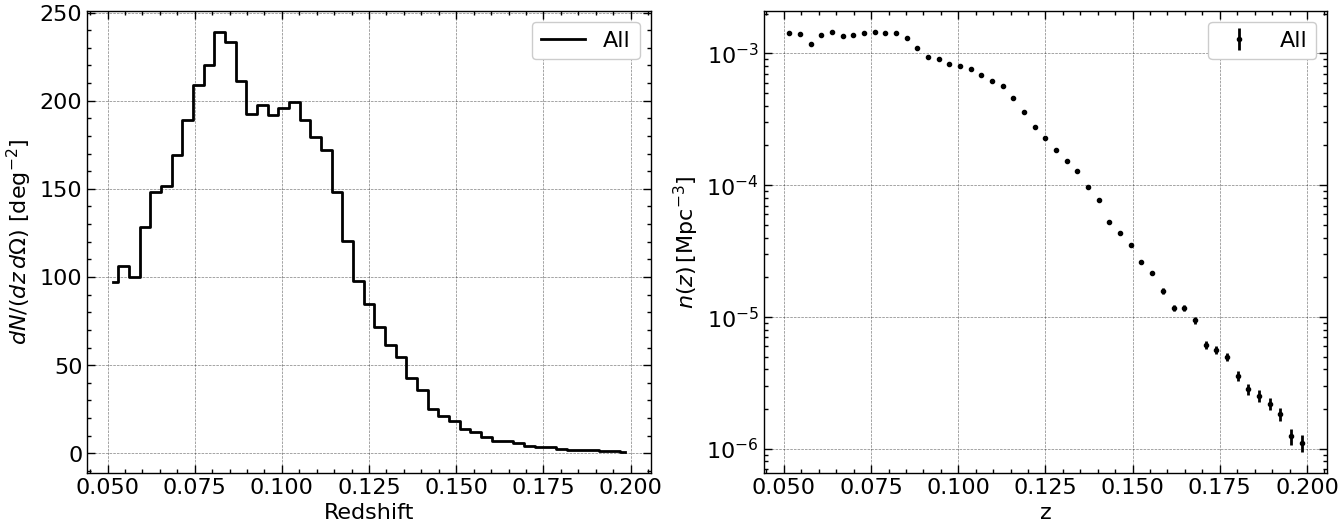

In [6]:
import pyccl as ccl

def plot_nz(z, area, zbins=np.linspace(0.05, 0.2, 50), cosmo=None,plot=False, label=None,axes=None, yscale='log', **kwargs):
    """
    Plot dN/(dz dOmega) and the comoving number density n(z).

    z     : redshifts of the sample (non-finite values are dropped)
    area  : sky area of the sample in deg^2
    zbins : redshift bin edges
    cosmo : pyccl Cosmology used for the comoving volume (default: same as above)
    axes  : pair of axes from a previous call, to overlay several samples

    Returns zcen, dN/(dz dOmega) [deg^-2], n(z) [Mpc^-3], axes
    """
    z = np.asarray(z, dtype=float)
    z = z[np.isfinite(z)]
    if cosmo is None:
        cosmo = ccl.Cosmology(Omega_c=0.264, Omega_b=0.049, h=0.674, sigma8=0.811, n_s=0.965)

    N, edges = np.histogram(z, bins=zbins)
    dz = np.diff(edges)
    zcen = 0.5*(edges[1:] + edges[:-1])
    dN_dz_dOmega = N / (area * dz)

    omega = area * (np.pi/180)**2      # sr
    chi = ccl.comoving_radial_distance(cosmo, 1/(1+edges))  # in Mpc
    volume = omega/3.0 * (chi[1:]**3 - chi[:-1]**3)
    n = N / volume
    n_err = np.sqrt(N) / volume        # Poisson
    if plot:
        if axes is None:
            fig, axes = plt.subplots(1, 2, figsize=(16, 6))

        axes[0].plot(zcen, dN_dz_dOmega, drawstyle='steps-mid', label=label, **kwargs)
        axes[0].set_xlabel('Redshift')
        axes[0].set_ylabel(r'$dN/(dz\, d\Omega)$ [deg$^{-2}$]')

        axes[1].errorbar(zcen, n, yerr=n_err, fmt='.', label=label, **kwargs)
        axes[1].set_yscale(yscale)
        axes[1].set_xlabel('z')
        axes[1].set_ylabel(r'$n(z)\,[{\rm Mpc}^{-3}]$')

        if label is not None:
            axes[0].legend()
            axes[1].legend()

    return zcen, dN_dz_dOmega, n, n_err, axes

# usage (z in any array-like, area in deg^2):



zcen, dN_dz_dOmega, n,n_err, axes = plot_nz(table['Z'][table['Z_SOURCE']!='NONE'], area_tot,plot=True, label='All', color='k')
# overlay several samples:
# _, _, _, axes = plot_nz(z_north, area_n, label='North', color='k')
# plot_nz(z_south, area_s, label='South', color='r', axes=axes)

Text(0.5, 0.98, 'Comparison of Spec and DR1 samples for full sample')

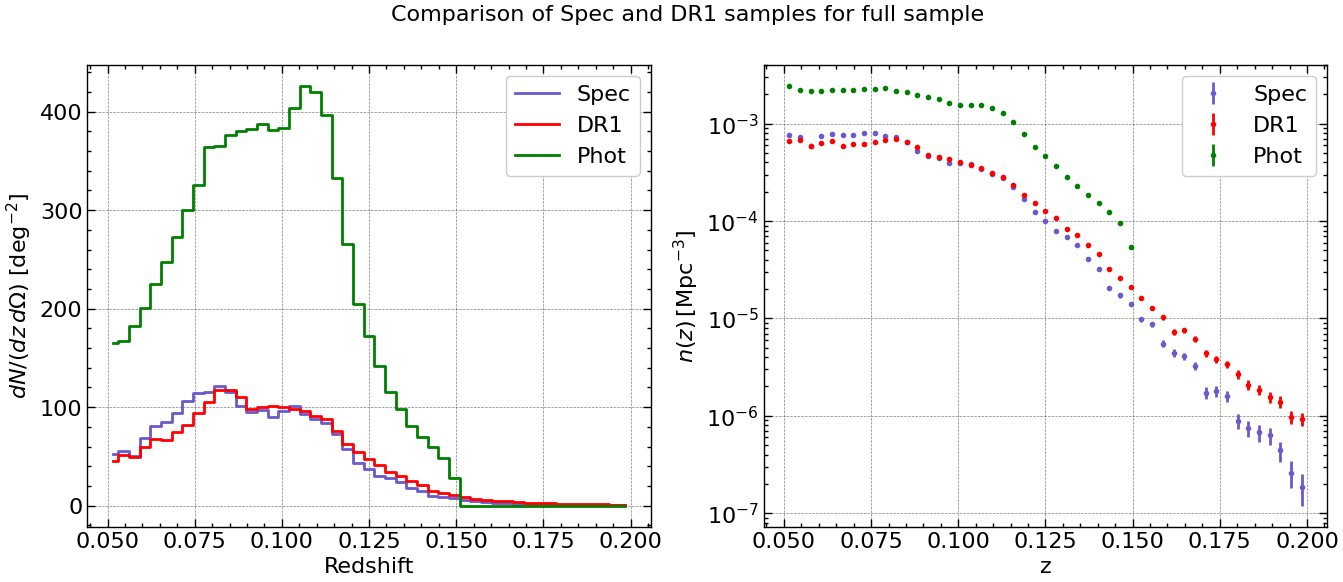

In [7]:
zcen_spec, dN_dz_dOmega_spec, n_spec,n_err_spec, _ = plot_nz(table['Z'][(table['Z_SOURCE']!='NONE')& (table['Z_SOURCE']!='DR1')], area_tot)
zcen_dr1, dN_dz_dOmega_dr1, n_dr1,n_err_dr1, _ = plot_nz(table['Z'][table['Z_SOURCE']=='DR1'], area_tot)
zcen_phot, dN_dz_dOmega_phot, n_phot,n_err_phot, _ = plot_nz(table['Z_PHOT_MEDIAN'], area_tot)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(zcen_spec, dN_dz_dOmega_spec, drawstyle='steps-mid', label='Spec',color = 'slateblue')
axes[0].plot(zcen_dr1, dN_dz_dOmega_dr1, drawstyle='steps-mid', label='DR1', color = 'red')
axes[0].plot(zcen_phot, dN_dz_dOmega_phot, drawstyle='steps-mid', label='Phot', color = 'green')
axes[0].set_xlabel('Redshift')
axes[0].set_ylabel(r'$dN/(dz\, d\Omega)$ [deg$^{-2}$]')
axes[0].legend()

axes[1].errorbar(zcen_spec, n_spec, yerr=n_err_spec, fmt='.', label='Spec', color = 'slateblue')
axes[1].errorbar(zcen_dr1, n_dr1, yerr=n_err_dr1, fmt='.', label='DR1', color = 'red')
axes[1].errorbar(zcen_phot, n_phot, yerr=n_err_phot, fmt='.', label='Phot', color = 'green')
axes[1].set_yscale('log')
axes[1].set_xlabel('z')
axes[1].set_ylabel(r'$n(z)\,[{\rm Mpc}^{-3}]$')
axes[1].legend()
plt.suptitle('Comparison of Spec and DR1 samples for full sample', fontsize=16)


In [8]:
region= {'N':table_north, 'S':table_south}
area = {'N':area_north, 'S':area_south}
dndz = {}
for reg in region.keys():
    zcen, dN_dz_dOmega, n,n_err, axes = plot_nz(region[reg]['Z'][region[reg]['Z_SOURCE']!='NONE'], area[reg],plot=False, label=reg, color='k')
    dndz[reg] = {'zcen': zcen, 'dN_dz_dOmega': dN_dz_dOmega, 'n': n, 'n_err': n_err}

Text(0.5, 0.98, 'Comparison of North and South samples for every avaialble redshift')

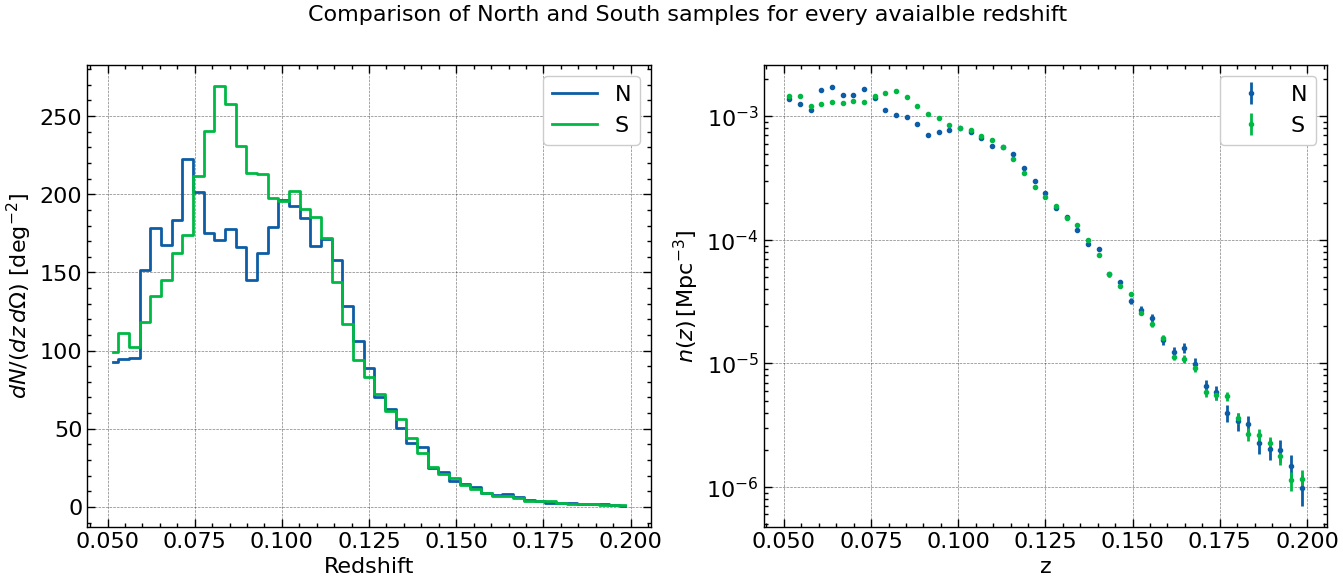

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for reg in region.keys():
    axes[0].plot(dndz[reg]['zcen'], dndz[reg]['dN_dz_dOmega'], drawstyle='steps-mid', label=reg)
    axes[0].set_xlabel('Redshift')
    axes[0].set_ylabel(r'$dN/(dz\, d\Omega)$ [deg$^{-2}$]')
    axes[0].legend()
    axes[1].errorbar(dndz[reg]['zcen'], dndz[reg]['n'], yerr=dndz[reg]['n_err'], fmt='.', label=reg)
    axes[1].set_yscale('log')
    axes[1].set_xlabel('z')
    axes[1].set_ylabel(r'$n(z)\,[{\rm Mpc}^{-3}]$')
    axes[1].legend()
plt.suptitle('Comparison of North and South samples for every avaialble redshift', fontsize=16)
    
    


In [ ]:
# same plot, only the FP galaxies whose redshift comes from DR1
# area: DR1 BGS clustering randoms split at DEC 32.375 (randoms/check_area.ipynb), not the imaging area
area_dr1 = {'N': 2285.6, 'S': 5187.7}

axes = None
for reg in region.keys():
    from_dr1 = region[reg]['Z_SOURCE'] == 'DR1'
    _, _, _, _, axes = plot_nz(region[reg]['Z'][from_dr1], area_dr1[reg], plot=True, label=reg, axes=axes)
plt.suptitle('Comparison of North and South samples for DR1 redshifts only', fontsize=16)

In [ ]:
# same plot for the whole DR1 BGS catalogue (no FP cuts)
dr1_bgs = np.concatenate([fitsio.FITS(f'/user/animesh.sah/DESI_PECVEL/desi_dr1_{cap}.fits')[1].read(columns=['DEC', 'Z'])
                          for cap in ['NGC', 'SGC']])
dr1_bgs_z = {'N': dr1_bgs['Z'][dr1_bgs['DEC'] >= 32.375], 'S': dr1_bgs['Z'][dr1_bgs['DEC'] < 32.375]}

axes = None
for reg in dr1_bgs_z.keys():
    _, _, _, _, axes = plot_nz(dr1_bgs_z[reg], area_dr1[reg], plot=True, label=reg, axes=axes)
plt.suptitle('Comparison of North and South for the full DR1 BGS catalogue', fontsize=16)

Text(0.5, 0.98, 'Comparison of North and South samples for photometric redshift')

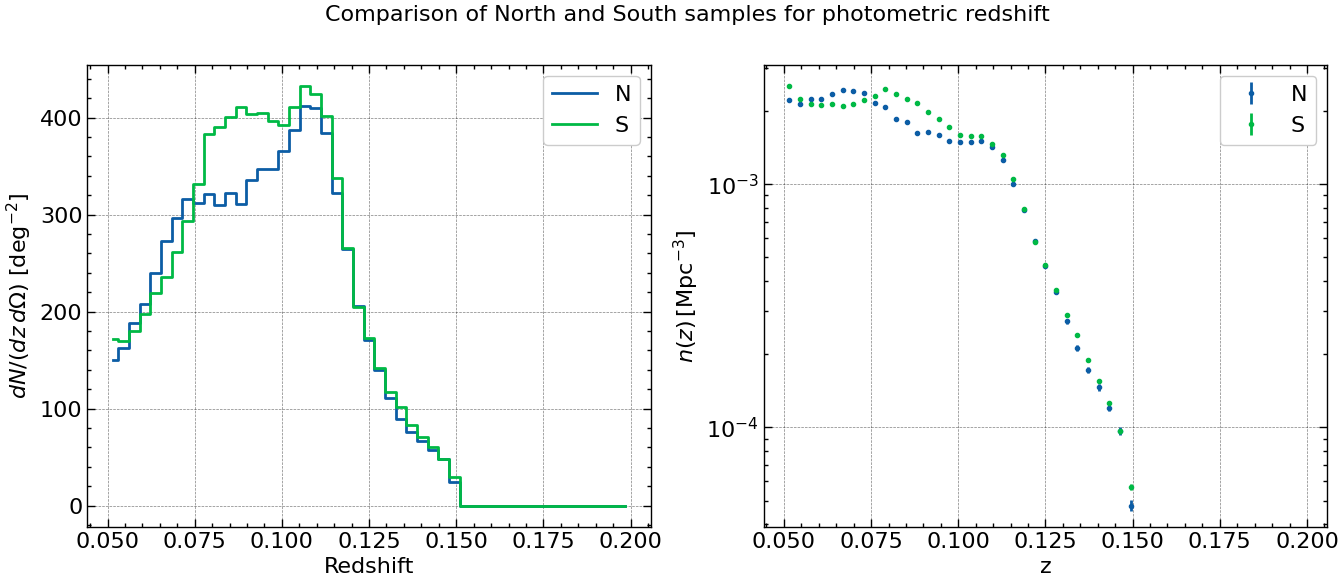

In [10]:

dndz = {}
for reg in region.keys():
    zcen, dN_dz_dOmega, n,n_err, axes = plot_nz(region[reg]['Z_PHOT_MEDIAN'], area[reg],plot=False, label=reg, color='k')
    dndz[reg] = {'zcen': zcen, 'dN_dz_dOmega': dN_dz_dOmega, 'n': n, 'n_err': n_err}
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for reg in region.keys():
    axes[0].plot(dndz[reg]['zcen'], dndz[reg]['dN_dz_dOmega'], drawstyle='steps-mid', label=reg)
    axes[0].set_xlabel('Redshift')
    axes[0].set_ylabel(r'$dN/(dz\, d\Omega)$ [deg$^{-2}$]')
    axes[0].legend()
    axes[1].errorbar(dndz[reg]['zcen'], dndz[reg]['n'], yerr=dndz[reg]['n_err'], fmt='.', label=reg)
    axes[1].set_yscale('log')
    axes[1].set_xlabel('z')
    axes[1].set_ylabel(r'$n(z)\,[{\rm Mpc}^{-3}]$')
    axes[1].legend()
plt.suptitle('Comparison of North and South samples for photometric redshift', fontsize=16)
    
    

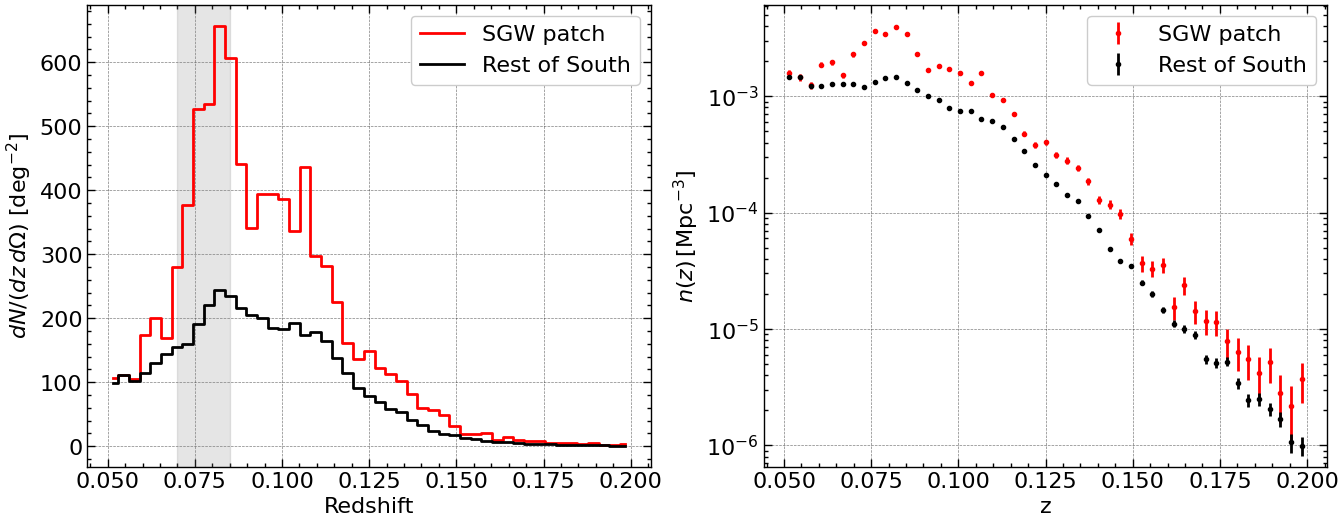

In [11]:
# Sloan Great Wall check: RA 140-212, DEC -5 to 5, z ~ 0.075
ra_lo, ra_hi, dec_lo, dec_hi = 140, 212, -5, 5
has_z = table_south['Z_SOURCE']!='NONE'
wall = (table_south['RA']>ra_lo) & (table_south['RA']<ra_hi) & (table_south['DEC']>dec_lo) & (table_south['DEC']<dec_hi)
wall_rand = (rand_south['RA']>ra_lo) & (rand_south['RA']<ra_hi) & (rand_south['DEC']>dec_lo) & (rand_south['DEC']<dec_hi)
area_wall = area_s * wall_rand.sum() / len(rand_south)   # deg^2, fraction of the South randoms scaled to area_s

_, _, _, _, axes = plot_nz(table_south['Z'][has_z & wall], area_wall, plot=True, label='SGW patch', color='r')
plot_nz(table_south['Z'][has_z & ~wall], area_s - area_wall, plot=True, label='Rest of South', color='k', axes=axes)
axes[0].axvspan(0.07, 0.085, color='gray', alpha=0.2)

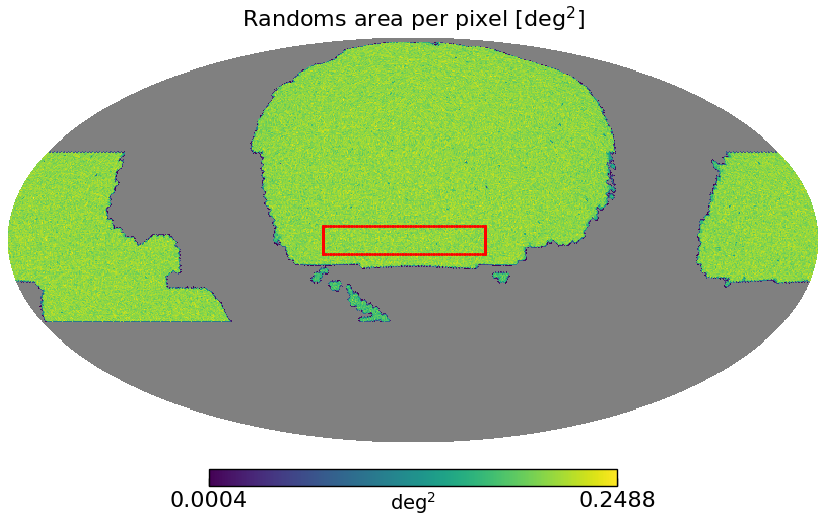

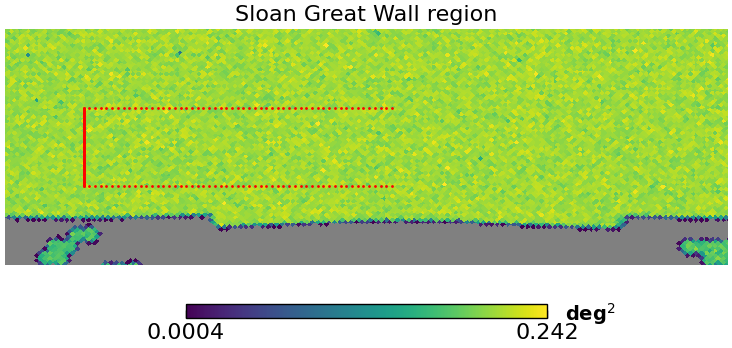

In [12]:
# randoms map (area covered per pixel) and the Sloan Great Wall box
import healpy as hp

nside = 128
rand_all = np.concatenate([rand_north['RA'], rand_south['RA']]), np.concatenate([rand_north['DEC'], rand_south['DEC']])
pix = hp.ang2pix(nside, rand_all[0], rand_all[1], lonlat=True)
area_map = np.bincount(pix, minlength=hp.nside2npix(nside)) / density      # deg^2 covered in each pixel
area_map[area_map == 0] = np.nan

hp.mollview(area_map, title='Randoms area per pixel [deg$^2$]', unit='deg$^2$', cmap='viridis', flip='geo', rot=180)
ra_edge = np.linspace(ra_lo, ra_hi, 100)
dec_edge = np.linspace(dec_lo, dec_hi, 100)
box_ra = np.concatenate([ra_edge, np.full(100, ra_hi), ra_edge[::-1], np.full(100, ra_lo)])
box_dec = np.concatenate([np.full(100, dec_lo), dec_edge, np.full(100, dec_hi), dec_edge[::-1]])
hp.projplot(box_ra, box_dec, 'r.', ms=2, lonlat=True)

# close-up of the box
hp.cartview(area_map, lonra=[ra_lo-10, ra_hi+10], latra=[dec_lo-10, dec_hi+10], title='Sloan Great Wall region', unit='deg$^2$', cmap='viridis', flip='geo')
hp.projplot(box_ra, box_dec, 'r.', ms=2, lonlat=True)

Text(0.5, 0.98, 'Comparison of Spec and DR1 samples for full sample')

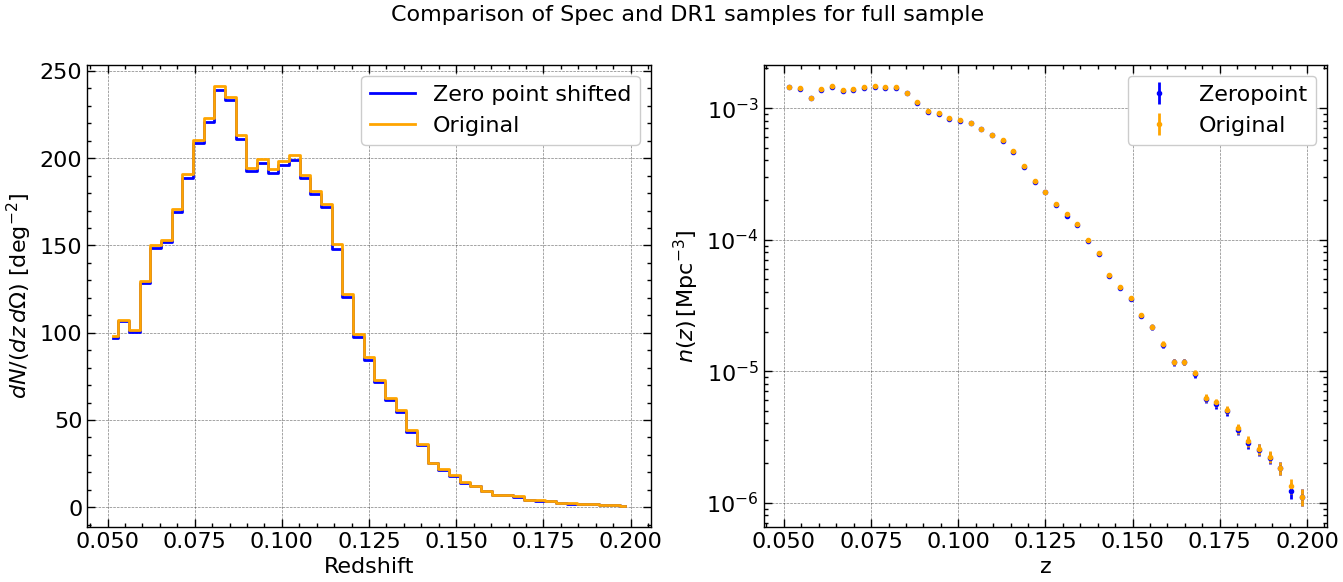

In [13]:
zcen_v1, dN_dz_dOmega_v1, n_v1,n_err_v1, _ = plot_nz(table['Z'][table['Z_SOURCE']!='NONE'], area_tot)
zcen_v0, dN_dz_dOmega_v0, n_v0,n_err_v0, _ = plot_nz(table_v0['Z'][table_v0['Z_SOURCE']!='NONE'], area_tot)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(zcen_v1, dN_dz_dOmega_v1, drawstyle='steps-mid', label='Zero point shifted', color = 'blue')
axes[0].plot(zcen_v0, dN_dz_dOmega_v0, drawstyle='steps-mid', label='Original', color = 'orange')
axes[0].set_xlabel('Redshift')
axes[0].set_ylabel(r'$dN/(dz\, d\Omega)$ [deg$^{-2}$]')
axes[0].legend()

axes[1].errorbar(zcen_v1, n_v1, yerr=n_err_v1, fmt='.', label='Zeropoint', color = 'blue')
axes[1].errorbar(zcen_v0, n_v0, yerr=n_err_v0, fmt='.', label='Original', color = 'orange')
axes[1].set_yscale('log')
axes[1].set_xlabel('z')
axes[1].set_ylabel(r'$n(z)\,[{\rm Mpc}^{-3}]$')
axes[1].legend()
plt.suptitle('Comparison of Spec and DR1 samples for full sample', fontsize=16)


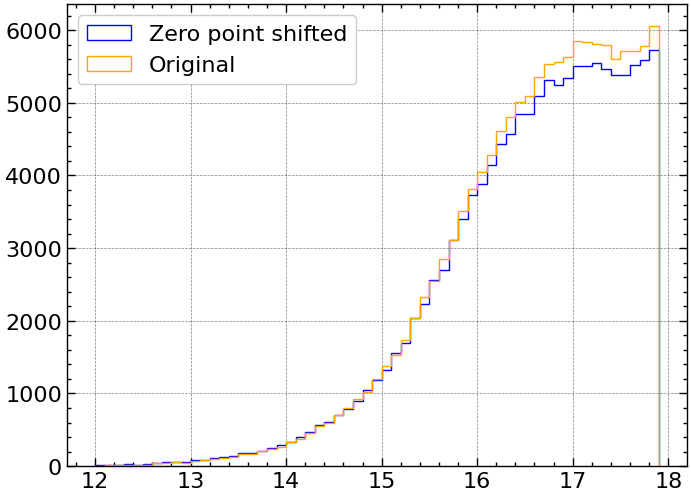

In [15]:
plt.hist(table_north['MAG_R'], bins=np.arange(12, 18, 0.1), histtype='step', label='Zero point shifted', color='blue')
plt.hist(table_north_v0['MAG_R'], bins=np.arange(12, 18, 0.1), histtype='step', label='Original', color='orange')
plt.legend()
